# Modelos generativos en biología — taller práctico

Vamos a construir un VAE **por piezas** y usarlo sobre datos reales de scRNA-seq (PBMCs de sangre periférica, ~2.700 células).

El taller tiene dos mitades:

1. **Un VAE sobre células.** Comprimimos cada célula a 2 números y miramos el mapa que resulta. Los tipos celulares aparecen solos, sin que nadie le dé etiquetas al modelo.
2. **Un VAE sobre genes** (la idea de [FAVA](https://doi.org/10.1093/bioinformatics/btae010)). Transponemos la matriz, comprimimos cada *gen*, y buscamos genes que se co-expresan correlacionando en el espacio latente en vez de en los datos crudos.

Lo que vas a escribir tú no son capas de PyTorch: son **decisiones de diseño**. El modelo está partido en encoder, decoder y prior, y cada uno se puede cambiar sin tocar los otros dos.

In [1]:
!pip install -q scanpy "pandas==2.2.3"

In [2]:
import numpy as np
import torch
import torch.nn as nn
import torch.distributions as D
import matplotlib.pyplot as plt
import scanpy as sc

torch.manual_seed(0)
np.random.seed(0)
plt.rcParams["figure.figsize"] = (6, 5)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
print("listo")

listo


## 1. Datos reales

`pbmc3k` son células mononucleares de sangre periférica de un donante sano, secuenciadas célula a célula. La versión `_processed` ya trae los tipos celulares anotados, que usaremos **sólo para colorear gráficos** — el modelo nunca los ve.

Usamos los valores log-normalizados: cada célula se escala al mismo total de lecturas y luego se aplica `log(1+x)`. Es la representación estándar y mantiene los valores positivos, que es lo que queremos para hablar de co-expresión.

In [3]:
adata = sc.datasets.pbmc3k_processed()

def a_denso(M):
    return np.asarray(M.toarray() if hasattr(M, "toarray") else M, dtype=np.float32)

# valores log-normalizados de los genes variables
X = a_denso(adata.raw[:, adata.var_names].X)
genes = np.array(adata.var_names)
presentes = set(genes)
tipos = adata.obs["louvain"].astype(str).values

print("matriz:", X.shape, "(células × genes)")
print("tipos celulares:", sorted(set(tipos)))
print(f"proporción de ceros: {(X == 0).mean():.1%}")

  0%|          | 0.00/23.5M [00:00<?, ?B/s]

matriz: (2638, 1838) (células × genes)
tipos celulares: ['B cells', 'CD14+ Monocytes', 'CD4 T cells', 'CD8 T cells', 'Dendritic cells', 'FCGR3A+ Monocytes', 'Megakaryocytes', 'NK cells']
proporción de ceros: 91.6%


Ese porcentaje de ceros es el problema central. Una célula no expresa todos sus genes a la vez, y además el protocolo pierde moléculas: muchos ceros son técnicos, no biológicos (*dropout*).

Mira qué le hace eso a un par de genes que **sabemos** que van juntos: CD79A y CD79B forman el mismo receptor de linfocito B. Están en el mismo complejo proteico.

In [4]:
def correlacion(a, b, matriz, nombres):
    i, j = list(nombres).index(a), list(nombres).index(b)
    return np.corrcoef(matriz[:, i], matriz[:, j])[0, 1]

for a, b in [("CD79A", "CD79B"), ("LYZ", "S100A9")]:
    if a in presentes and b in presentes:
        print(f"{a} vs {b} (datos crudos): r = {correlacion(a, b, X, genes):.3f}")

CD79A vs CD79B (datos crudos): r = 0.687


Correlaciones modestas para genes del mismo complejo. Guarda esos números: los vamos a recalcular al final sobre el espacio latente.

## 2. El método, en piezas

Aquí está todo el modelo. Fíjate en que **nadie escribe un VAE**: se escriben tres objetos independientes y luego se ensamblan.

| Pieza | Qué recibe | Qué devuelve | Qué decides al cambiarla |
| --- | --- | --- | --- |
| `Encoder` | `x` | la distribución `q(z\|x)` | cómo se lee el dato |
| `Decoder` | `z` | la distribución `p(x\|z)` | **qué tipo de dato es** (gaussiano, conteos…) |
| `Prior` | — | `p(z)` | qué forma tiene el espacio latente |

La convención clave: encoder y decoder devuelven **distribuciones de `torch.distributions`**, no tensores. Eso es lo que permite cambiar una pieza por otra sin tocar la función de pérdida.

In [5]:
def mlp(dims, act=nn.ReLU):
    capas = []
    for i in range(len(dims) - 1):
        capas += [nn.Linear(dims[i], dims[i + 1]), act()]
    return nn.Sequential(*capas)


class MLPEncoder(nn.Module):
    '''x -> q(z|x). Devuelve una DISTRIBUCIÓN, no un vector.'''
    def __init__(self, input_dim, latent_dim, hidden=(256,), act=nn.ReLU):
        super().__init__()
        self.cuerpo = mlp([input_dim, *hidden], act=act)
        self.a_mu = nn.Linear(hidden[-1], latent_dim)
        self.a_logvar = nn.Linear(hidden[-1], latent_dim)

    def forward(self, x):
        h = self.cuerpo(x)
        logvar = self.a_logvar(h).clamp(-10.0, 10.0)
        return D.Normal(self.a_mu(h), torch.exp(0.5 * logvar))


class GaussianDecoder(nn.Module):
    '''z -> p(x|z) gaussiana, con una escala aprendida por gen.'''
    def __init__(self, latent_dim, output_dim, hidden=(256,), act=nn.ReLU):
        super().__init__()
        self.cuerpo = mlp([latent_dim, *hidden], act=act)
        self.a_media = nn.Linear(hidden[-1], output_dim)
        self.log_escala = nn.Parameter(torch.zeros(output_dim))

    def forward(self, z):
        media = self.a_media(self.cuerpo(z))
        return D.Normal(media, torch.exp(self.log_escala).clamp(min=1e-3))


class StandardNormalPrior(nn.Module):
    '''p(z) = N(0, I): el prior por defecto de un VAE.'''
    def __init__(self, latent_dim):
        super().__init__()
        self.register_buffer("loc", torch.zeros(latent_dim))
        self.register_buffer("escala", torch.ones(latent_dim))

    def forward(self):
        return D.Independent(D.Normal(self.loc, self.escala), 1)

In [6]:
class VAE(nn.Module):
    '''No sabe nada de sus piezas: sólo las conecta.'''
    def __init__(self, encoder, decoder, prior):
        super().__init__()
        self.encoder, self.decoder, self.prior = encoder, decoder, prior

    def forward(self, x):
        q = self.encoder(x)
        z = q.rsample()          # truco de reparametrización, incluido en rsample()
        return q, z, self.decoder(z)

    @torch.no_grad()
    def representar(self, x):
        return self.encoder(x).mean    # la media de q(z|x) como coordenada del dato


def loss_elbo(modelo, x, beta=1.0):
    '''-ELBO. Cada término es una frase: 'reconstruye' y 'mantén el mapa ordenado'.'''
    q, z, p_x = modelo(x)
    recon = p_x.log_prob(x).sum(-1)                        # qué tan probable es x bajo p(x|z)
    kl = q.log_prob(z).sum(-1) - modelo.prior().log_prob(z)  # KL por Monte Carlo
    return -(recon - beta * kl).mean(), recon.mean().item(), kl.mean().item()

El KL se calcula por **Monte Carlo** (una muestra), en vez de con la fórmula cerrada para gaussianas. Es un poco más ruidoso, pero funciona con *cualquier* prior que sepa calcular `log_prob`. Esa única decisión es la que te deja cambiar el prior más adelante sin reescribir nada.

In [7]:
def entrenar(modelo, datos, epochs=60, lr=1e-3, batch_size=128, beta=1.0, verbose=True):
    X_t = torch.as_tensor(datos, dtype=torch.float32)
    opt = torch.optim.Adam(modelo.parameters(), lr=lr)
    historia = []
    for ep in range(epochs):
        perm = torch.randperm(len(X_t))
        acum = []
        for i in range(0, len(X_t), batch_size):
            lote = X_t[perm[i:i + batch_size]]
            opt.zero_grad()
            perdida, recon, kl = loss_elbo(modelo, lote, beta=beta)
            perdida.backward()
            opt.step()
            acum.append((perdida.item(), recon, kl))
        historia.append(np.mean(acum, axis=0))
        if verbose and (ep % 10 == 0 or ep == epochs - 1):
            p, r, k = historia[-1]
            print(f"época {ep:3d} | -ELBO {p:9.1f} | recon {r:9.1f} | KL {k:7.2f}")
    return np.array(historia)

## 3. Primer modelo: un mapa de células

`latent_dim=2` para poder dibujar el espacio latente directamente, sin UMAP ni PCA de por medio. Lo que veas **es** el espacio que aprendió el modelo, no una proyección de él.

In [8]:
n_genes = X.shape[1]

vae_celulas = VAE(
    encoder=MLPEncoder(n_genes, latent_dim=2, hidden=(256, 64)),
    decoder=GaussianDecoder(2, n_genes, hidden=(64, 256)),
    prior=StandardNormalPrior(2),
)

hist = entrenar(vae_celulas, X, epochs=200)

época   0 | -ELBO    1734.7 | recon   -1733.6 | KL    1.08
época  10 | -ELBO    1354.5 | recon   -1351.8 | KL    2.63
época  20 | -ELBO    1006.6 | recon   -1003.3 | KL    3.35
época  30 | -ELBO     680.9 | recon    -677.1 | KL    3.78
época  40 | -ELBO     382.7 | recon    -378.5 | KL    4.21
época  50 | -ELBO     117.3 | recon    -112.7 | KL    4.58
época  60 | -ELBO    -113.3 | recon     118.2 | KL    4.91
época  70 | -ELBO    -306.8 | recon     312.0 | KL    5.18
época  80 | -ELBO    -462.4 | recon     468.0 | KL    5.54
época  90 | -ELBO    -586.0 | recon     591.7 | KL    5.67
época 100 | -ELBO    -680.3 | recon     686.1 | KL    5.88
época 110 | -ELBO    -749.3 | recon     755.3 | KL    6.06
época 120 | -ELBO    -804.3 | recon     810.5 | KL    6.17
época 130 | -ELBO    -840.7 | recon     847.1 | KL    6.47
época 140 | -ELBO    -867.4 | recon     873.9 | KL    6.53
época 150 | -ELBO    -891.0 | recon     897.7 | KL    6.68
época 160 | -ELBO    -899.5 | recon     906.3 | KL    6.

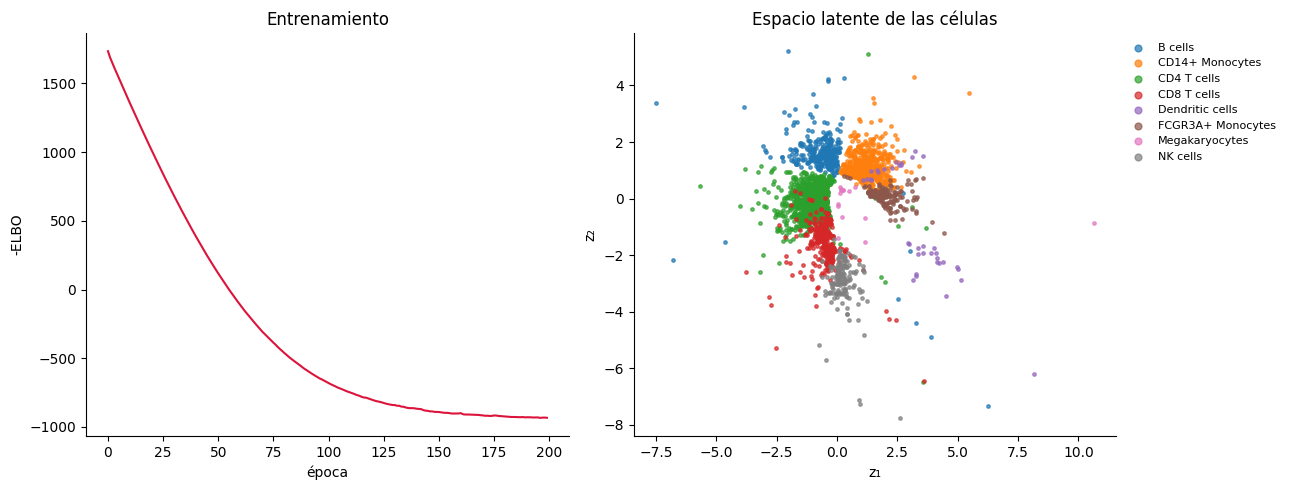

In [9]:
def dibujar_latente(Z, etiquetas, titulo, ax=None):
    ax = ax or plt.gca()
    for nombre in sorted(set(etiquetas)):
        m = etiquetas == nombre
        ax.scatter(Z[m, 0], Z[m, 1], s=6, alpha=0.7, label=nombre)
    ax.set_xlabel("z₁"); ax.set_ylabel("z₂"); ax.set_title(titulo)
    ax.legend(markerscale=2, fontsize=8, frameon=False, bbox_to_anchor=(1, 1))
    return ax

Z_cel = vae_celulas.representar(torch.as_tensor(X)).numpy()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].plot(hist[:, 0], color="crimson")
axes[0].set_xlabel("época"); axes[0].set_ylabel("-ELBO"); axes[0].set_title("Entrenamiento")
dibujar_latente(Z_cel, tipos, "Espacio latente de las células", ax=axes[1])
plt.tight_layout(); plt.show()

**Esto es lo que había que ver.** El modelo recibió una matriz de números sin ninguna etiqueta, y los tipos celulares se separaron solos. La única instrucción que tenía era *comprime a 2 números de forma que puedas reconstruir la célula*; para lograrlo tuvo que descubrir que hay tipos celulares.

Comprueba que el mapa es continuo y no un montón de puntos sueltos: decodifica puntos de una recta entre dos regiones y mira qué sale.

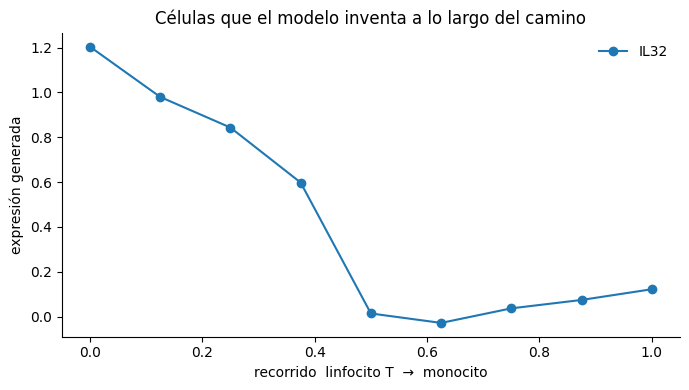

In [10]:
# caminar por el espacio latente entre dos tipos celulares
def centro(nombre):
    m = np.array([nombre.lower() in t.lower() for t in tipos])
    return Z_cel[m].mean(0)

origen, destino = centro("CD4 T"), centro("CD14+ Mono")
pasos = np.linspace(0, 1, 9)[:, None]
camino = torch.as_tensor((1 - pasos) * origen + pasos * destino, dtype=torch.float32)

with torch.no_grad():
    generadas = vae_celulas.decoder(camino).mean.numpy()

marcadores = [g for g in ["IL32", "CD3D", "LYZ", "S100A9"] if g in presentes]
plt.figure(figsize=(7, 4))
for m in marcadores:
    plt.plot(pasos.ravel(), generadas[:, list(genes).index(m)], marker="o", label=m)
plt.xlabel("recorrido  linfocito T  →  monocito")
plt.ylabel("expresión generada")
plt.title("Células que el modelo inventa a lo largo del camino")
plt.legend(frameon=False); plt.tight_layout(); plt.show()

Ninguna de esas células existe en los datos: las generó el decoder. Los marcadores de linfocito T bajan mientras los de monocito suben, de forma suave. El modelo no aprendió genes por separado, aprendió **cómo dependen unos de otros**.

## 4. Segundo modelo: FAVA, el mismo código sobre genes

Hasta aquí cada célula era una muestra. Ahora transponemos: **cada gen es una muestra**, descrita por sus valores a lo largo de 2.638 células. Comprimimos ese vector largo y ruidoso a unas pocas dimensiones, y después buscamos genes cercanos en ese espacio.

Esta es la idea de FAVA, y es también la demostración de que el diseño modular sirve: el único cambio es qué matriz entra y las dimensiones. Las clases son exactamente las mismas.

In [11]:
Xg = X.T.copy()                      # genes × células
Xg = Xg / (Xg.std(axis=1, keepdims=True) + 1e-6)   # cada gen en la misma escala
n_celulas = Xg.shape[1]
DIM_LATENTE = 16

vae_genes = VAE(
    encoder=MLPEncoder(n_celulas, DIM_LATENTE, hidden=(512, 128)),
    decoder=GaussianDecoder(DIM_LATENTE, n_celulas, hidden=(128, 512)),
    prior=StandardNormalPrior(DIM_LATENTE),
)

hist_g = entrenar(vae_genes, Xg, epochs=80, batch_size=64)
Z_gen = vae_genes.representar(torch.as_tensor(Xg)).numpy()
print("cada gen es ahora un vector de", Z_gen.shape[1], "números")

época   0 | -ELBO    3755.5 | recon   -3749.2 | KL    6.32
época  10 | -ELBO    3580.5 | recon   -3571.6 | KL    8.91
época  20 | -ELBO    3533.2 | recon   -3522.7 | KL   10.42
época  30 | -ELBO    3500.5 | recon   -3486.9 | KL   13.59
época  40 | -ELBO    3462.6 | recon   -3443.5 | KL   19.11
época  50 | -ELBO    3413.9 | recon   -3388.7 | KL   25.15
época  60 | -ELBO    3354.0 | recon   -3323.8 | KL   30.14
época  70 | -ELBO    3303.4 | recon   -3269.8 | KL   33.58
época  79 | -ELBO    3256.1 | recon   -3220.5 | KL   35.57
cada gen es ahora un vector de 16 números


Para ver este espacio necesitamos bajarlo a 2D (son 16 dimensiones). Coloreamos con familias de marcadores **conocidas de antemano**: si el modelo funciona, los genes de la misma familia deberían caer juntos sin que se lo hayamos pedido.

{'linfocito B': 3, 'monocito': 3, 'linfocito T': 2, 'NK / citotox': 5, 'plaqueta': 2}


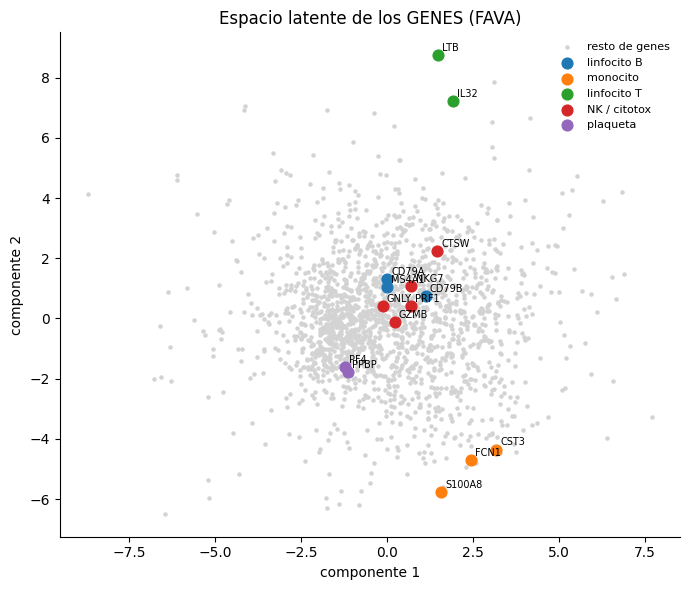

In [12]:
familias = {
    "linfocito B":  ["CD79A", "CD79B", "MS4A1", "HLA-DRA", "CD74"],
    "monocito":     ["LYZ", "S100A8", "S100A9", "CST3", "FCN1"],
    "linfocito T":  ["CD3D", "CD3E", "IL7R", "IL32", "LTB"],
    "NK / citotox": ["GNLY", "NKG7", "GZMB", "PRF1", "CTSW"],
    "plaqueta":     ["PPBP", "PF4"],
}
familias = {k: [g for g in v if g in presentes] for k, v in familias.items()}
familias = {k: v for k, v in familias.items() if len(v) >= 2}
print({k: len(v) for k, v in familias.items()})

# PCA sobre el latente, sólo para poder dibujarlo
Zc = Z_gen - Z_gen.mean(0)
U, S, Vt = np.linalg.svd(Zc, full_matrices=False)
Z2 = Zc @ Vt[:2].T

idx = {g: i for i, g in enumerate(genes)}
plt.figure(figsize=(7, 6))
plt.scatter(Z2[:, 0], Z2[:, 1], s=5, color="lightgray", label="resto de genes")
for nombre, lista in familias.items():
    ii = [idx[g] for g in lista]
    plt.scatter(Z2[ii, 0], Z2[ii, 1], s=60, label=nombre)
    for g in lista:
        plt.annotate(g, Z2[idx[g], :2], fontsize=7, xytext=(3, 3), textcoords="offset points")
plt.title("Espacio latente de los GENES (FAVA)")
plt.xlabel("componente 1"); plt.ylabel("componente 2")
plt.legend(frameon=False, fontsize=8); plt.tight_layout(); plt.show()

## 5. ¿Ganamos algo? La prueba que importa

Un gráfico bonito no es evidencia. La pregunta concreta: **¿separa mejor el espacio latente los pares reales de los pares al azar que los datos crudos?**

Comparamos dos conjuntos de pares:

- **Pares conocidos:** genes de la misma familia de marcadores.
- **Pares al azar:** parejas de genes cualesquiera.

Un buen método debería subir los primeros sin subir los segundos.

crudo    | conocidos r̄ = +0.674 | azar r̄ = +0.012 | separación = +0.663
latente  | conocidos r̄ = +0.911 | azar r̄ = -0.007 | separación = +0.918


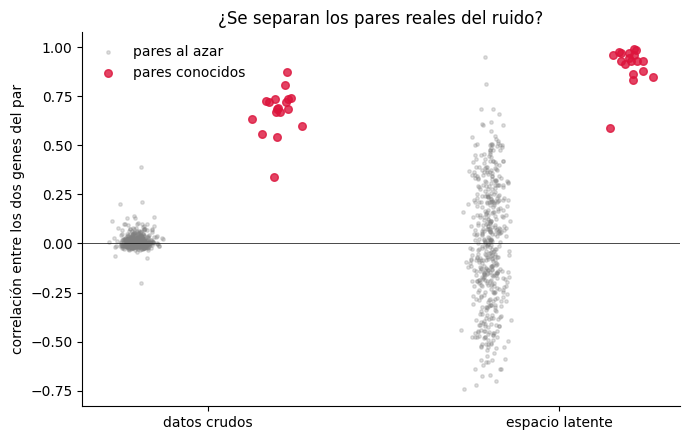

In [13]:
def pares_conocidos(familias, idx):
    out = []
    for lista in familias.values():
        for a in range(len(lista)):
            for b in range(a + 1, len(lista)):
                out.append((idx[lista[a]], idx[lista[b]]))
    return out

def r_de_pares(pares, M):
    M = M - M.mean(1, keepdims=True)
    M = M / (np.linalg.norm(M, axis=1, keepdims=True) + 1e-9)
    return np.array([float(M[i] @ M[j]) for i, j in pares])

conocidos = pares_conocidos(familias, idx)
rng = np.random.default_rng(0)
azar = [tuple(rng.choice(len(genes), 2, replace=False)) for _ in range(500)]

resultados = {
    "crudo": (r_de_pares(conocidos, Xg), r_de_pares(azar, Xg)),
    "latente": (r_de_pares(conocidos, Z_gen), r_de_pares(azar, Z_gen)),
}

fig, ax = plt.subplots(figsize=(7, 4.5))
for k, (espacio, (con, az)) in enumerate(resultados.items()):
    ax.scatter(np.full(len(az), k * 2) + rng.normal(0, .05, len(az)), az,
               s=6, alpha=.25, color="gray", label="pares al azar" if k == 0 else None)
    ax.scatter(np.full(len(con), k * 2 + .8) + rng.normal(0, .05, len(con)), con,
               s=30, alpha=.8, color="crimson", label="pares conocidos" if k == 0 else None)
    print(f"{espacio:8s} | conocidos r̄ = {con.mean():+.3f} | azar r̄ = {az.mean():+.3f} "
          f"| separación = {con.mean() - az.mean():+.3f}")
ax.set_xticks([0.4, 2.4]); ax.set_xticklabels(["datos crudos", "espacio latente"])
ax.axhline(0, color="black", lw=.5)
ax.set_ylabel("correlación entre los dos genes del par")
ax.set_title("¿Se separan los pares reales del ruido?")
ax.legend(frameon=False); plt.tight_layout(); plt.show()

La cifra que importa es la **separación**: cuánto se despegan los pares conocidos de los pares al azar. Si sube en el espacio latente, la compresión quitó ruido sin quitar biología — que es exactamente lo que afirma FAVA.

Un detalle honesto: FAVA se queda con la cola **positiva** de la correlación (genes que se co-expresan). La cola negativa también existe, y en estos datos suele corresponder a tipos celulares mutuamente excluyentes. No es lo que el método publicado reporta, pero merece una mirada.

In [14]:
# los pares más fuertes del espacio latente, en ambos extremos
Zn = Z_gen - Z_gen.mean(1, keepdims=True)
Zn = Zn / (np.linalg.norm(Zn, axis=1, keepdims=True) + 1e-9)
R = Zn @ Zn.T
np.fill_diagonal(R, 0)

iu = np.triu_indices_from(R, k=1)
orden = np.argsort(R[iu])

def mostrar(titulo, seleccion):
    print(titulo)
    for k in seleccion:
        i, j = iu[0][k], iu[1][k]
        print(f"   {genes[i]:>10s} — {genes[j]:<10s}  r = {R[i, j]:+.3f}")

mostrar("Co-expresión más fuerte:", orden[-10:][::-1])
mostrar("\nExclusión más fuerte:", orden[:10])

Co-expresión más fuerte:
       TREML1 — ITGA2B      r = +0.998
         C1QA — C1QB        r = +0.997
         SDPR — AP001189.4  r = +0.997
      C2orf88 — ESAM        r = +0.996
     HLA-DRB1 — HLA-DPA1    r = +0.996
          GP9 — AP001189.4  r = +0.996
          PF4 — ITGA2B      r = +0.996
       SPOCD1 — ESAM        r = +0.995
       SPOCD1 — C2orf88     r = +0.995
          PF4 — TREML1      r = +0.994

Exclusión más fuerte:
        RAB34 — BZRAP1-AS1  r = -0.953
       ANTXR2 — METTL3      r = -0.936
        GSTO1 — BCDIN3D     r = -0.936
        KLHL6 — LITAF       r = -0.932
         LST1 — RP11-291B21.2  r = -0.918
       FCGR2A — RP11-291B21.2  r = -0.917
         KLC4 — ORMDL2      r = -0.915
     PLA2G12A — ZBP1        r = -0.915
     ATP6V0E1 — RP11-493L12.4  r = -0.909
        SURF1 — MIS18BP1    r = -0.909


> **Valida tú mismo.** Toma dos o tres pares de la primera lista y búscalos en [STRING](https://string-db.org). Si ya se conocen como asociados, tu modelo recuperó biología real. Si no aparecen, puede ser un falso positivo — o algo que mirar.

## 6. Diseño de métodos: cambia las piezas

Aquí empieza la parte interesante. Todo lo anterior salió de tres objetos; cambiar cualquiera da un método distinto. No hay que tocar `VAE`, `loss_elbo` ni `entrenar`.

### 6.1 Otro prior

`N(0, I)` empuja todo hacia una sola mancha centrada. Pero si los datos tienen grupos, un prior con grupos los representa mejor. Una mezcla de gaussianas es un cambio de **una línea** al construir el modelo.

época   0 | -ELBO    1736.9 | recon   -1736.2 | KL    0.69
época  10 | -ELBO    1354.2 | recon   -1351.6 | KL    2.59
época  20 | -ELBO    1006.5 | recon   -1003.3 | KL    3.17
época  30 | -ELBO     680.6 | recon    -677.0 | KL    3.57
época  40 | -ELBO     381.6 | recon    -377.7 | KL    3.87
época  50 | -ELBO     115.3 | recon    -111.1 | KL    4.21
época  60 | -ELBO    -114.9 | recon     119.4 | KL    4.52
época  70 | -ELBO    -306.9 | recon     311.6 | KL    4.68
época  80 | -ELBO    -464.6 | recon     469.5 | KL    4.97
época  90 | -ELBO    -587.5 | recon     592.7 | KL    5.19
época 100 | -ELBO    -680.7 | recon     686.1 | KL    5.37
época 110 | -ELBO    -754.0 | recon     759.5 | KL    5.55
época 120 | -ELBO    -804.0 | recon     809.7 | KL    5.68
época 130 | -ELBO    -840.9 | recon     846.9 | KL    5.98
época 140 | -ELBO    -876.6 | recon     882.7 | KL    6.08
época 150 | -ELBO    -891.0 | recon     897.2 | KL    6.21
época 160 | -ELBO    -910.0 | recon     916.2 | KL    6.

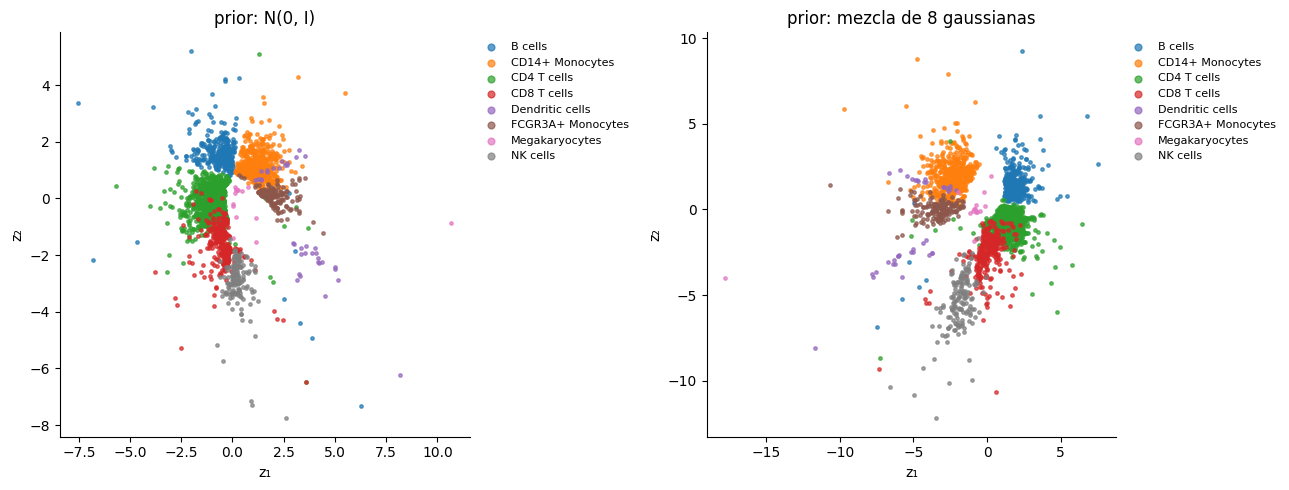

In [15]:
class MixtureOfGaussiansPrior(nn.Module):
    '''p(z) = mezcla de K gaussianas, con medias y pesos APRENDIDOS.'''
    def __init__(self, latent_dim, n_componentes=10):
        super().__init__()
        self.medias = nn.Parameter(torch.randn(n_componentes, latent_dim))
        self.log_escalas = nn.Parameter(torch.zeros(n_componentes, latent_dim))
        self.pesos = nn.Parameter(torch.zeros(n_componentes))

    def forward(self):
        comp = D.Independent(
            D.Normal(self.medias, torch.exp(self.log_escalas).clamp(min=1e-3)), 1)
        return D.MixtureSameFamily(D.Categorical(logits=self.pesos), comp)


vae_mog = VAE(
    encoder=MLPEncoder(n_genes, 2, hidden=(256, 64)),
    decoder=GaussianDecoder(2, n_genes, hidden=(64, 256)),
    prior=MixtureOfGaussiansPrior(2, n_componentes=8),   # <-- la única diferencia
)
entrenar(vae_mog, X, epochs=200, verbose=True)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
dibujar_latente(Z_cel, tipos, "prior: N(0, I)", ax=axes[0])
dibujar_latente(vae_mog.representar(torch.as_tensor(X)).numpy(), tipos,
                "prior: mezcla de 8 gaussianas", ax=axes[1])
plt.tight_layout(); plt.show()

Compara los dos mapas. ¿Los grupos quedan más separados? ¿Más compactos? ¿Cambió algo? No hay una respuesta correcta garantizada — eso es investigación, y acabas de hacer un experimento.

### 6.2 Ejercicios

Cada uno es una pieza nueva que encaja en el mismo `VAE(...)`.

In [ ]:
# --- EJERCICIO 1: encoder con conexiones residuales ---
# Un bloque residual calcula f(x) + x, en vez de f(x). Permite redes más
# profundas sin que la señal se degrade.

class BloqueResidual(nn.Module):
    def __init__(self, dim, act=nn.ReLU):
        super().__init__()
        self.f = nn.Sequential(nn.Linear(dim, dim), act(), nn.Linear(dim, dim))
        self.act = act()

    def forward(self, x):
        return ...          # TODO: devuelve la suma de x con f(x), pasada por la activación


class ResidualEncoder(nn.Module):
    def __init__(self, input_dim, latent_dim, ancho=256, n_bloques=2):
        super().__init__()
        self.entrada = nn.Sequential(nn.Linear(input_dim, ancho), nn.ReLU())
        self.bloques = nn.Sequential(*[BloqueResidual(ancho) for _ in range(n_bloques)])
        self.a_mu = nn.Linear(ancho, latent_dim)
        self.a_logvar = nn.Linear(ancho, latent_dim)

    def forward(self, x):
        h = self.bloques(self.entrada(x))
        # TODO: devuelve una D.Normal, igual que MLPEncoder
        return ...

# cuando funcione:
# vae_res = VAE(ResidualEncoder(n_genes, 2), GaussianDecoder(2, n_genes), StandardNormalPrior(2))

In [ ]:
# --- EJERCICIO 2: decoder de conteos ---
# Los conteos de RNA no son gaussianos: son enteros, dispersos y sobredispersos.
# La binomial negativa es la distribución que de verdad les corresponde.
# Pista: necesitas una media positiva (softplus o exp) y una dispersión por gen.

class NegativeBinomialDecoder(nn.Module):
    def __init__(self, latent_dim, output_dim, hidden=(256,)):
        super().__init__()
        self.cuerpo = mlp([latent_dim, *hidden])
        self.a_media = nn.Linear(hidden[-1], output_dim)
        self.log_theta = nn.Parameter(torch.zeros(output_dim))   # dispersión por gen

    def forward(self, z):
        media = torch.nn.functional.softplus(self.a_media(self.cuerpo(z))) + 1e-4
        theta = torch.exp(self.log_theta).clamp(1e-3, 1e4)
        # TODO: construye D.NegativeBinomial a partir de (media, theta).
        # PyTorch la parametriza con total_count=theta y logits=log(media) - log(theta).
        return ...

# Ojo: este decoder necesita CONTEOS CRUDOS como entrada, no datos log-normalizados.
# Los tienes en adata.raw antes de normalizar — ¿cambia el espacio latente?

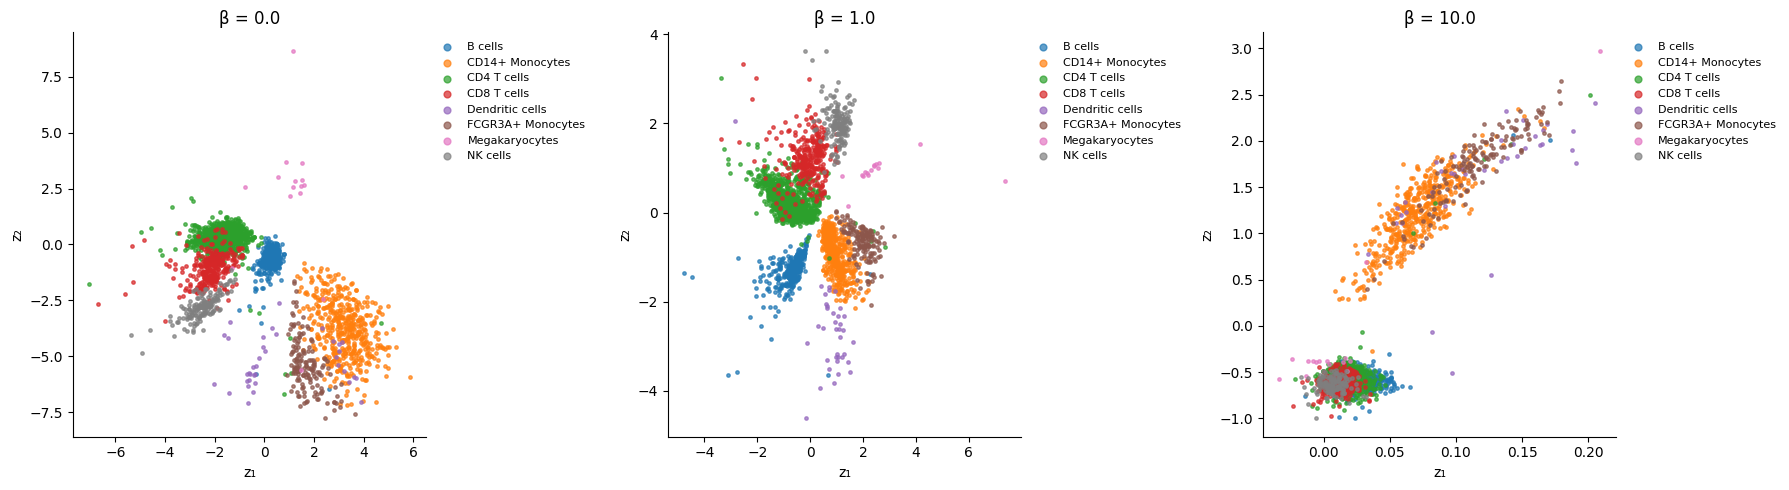

In [16]:
# --- EJERCICIO 3: ¿cuánto pesa el KL? ---
# beta controla el equilibrio entre reconstruir y ordenar el mapa.
# Entrena con beta = 0, 1 y 10, y dibuja los tres espacios latentes.
# Antes de ejecutar, ESCRIBE tu predicción:
#   beta = 0   -> ...
#   beta = 10  -> ...

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, b in zip(axes, [0.0, 1.0, 10.0]):
    m = VAE(MLPEncoder(n_genes, 2, hidden=(256, 64)),
            GaussianDecoder(2, n_genes, hidden=(64, 256)),
            StandardNormalPrior(2))
    entrenar(m, X, epochs=40, beta=b, verbose=False)
    dibujar_latente(m.representar(torch.as_tensor(X)).numpy(), tipos, f"β = {b}", ax=ax)
plt.tight_layout(); plt.show()

### 6.3 Ideas para seguir

- **Condicionar el modelo.** Pásale al encoder y al decoder una variable extra (el lote, el donante, la especie) y pídele el contrafactual: *¿cómo se vería esta célula si viniera del otro lote?* Ese es el mecanismo de la corrección de efectos de lote.
- **Añadir un discriminador.** Si una red adivina el lote a partir de `z`, penaliza al encoder. Cuando deje de adivinarlo, en `z` sólo queda biología. Eso es ABaCo.
- **Cambiar la pérdida, no la red.** Cada término que añades a `perdida_elbo` es una intención que le escribes al modelo. Diseñar un método es, casi siempre, escribir la pérdida correcta.

## Cierre

Lo que construiste es, en estructura, el mismo objeto que hay detrás de scVI, de FAVA y de los métodos de traducción entre especies: un encoder, un decoder, un prior y una pérdida que dice qué te importa.

Y lo más importante del taller no es el modelo, es el paso 5: un modelo generativo produce **hipótesis**, no mediciones. Un par de genes que sale de aquí es una propuesta que hay que contrastar.